## 1. 파일 불러오기

In [2]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

raw_df = pd.read_csv("./nepal_building_damage.csv")

print(raw_df.shape)

df = raw_df.drop(columns=['building_id'])

(260601, 40)


In [3]:
# 데이터 분할(학습:검증:테스트)

X = df.drop(columns=["damage_grade"])
y = df["damage_grade"]
y = df["damage_grade"] - 1 


# 1) 데이터 분할 ; 학습, 검증, 테스트 세트로 분할
# 1차 분할: 학습 70%, 나머지 30%
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y) 

# 2차 분할: 검증 15%, 테스트 15%
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp) 

print("Train set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Train set shape: (182420, 38) (182420,)
Validation set shape: (39090, 38) (39090,)
Test set shape: (39091, 38) (39091,)


## 2. 베이스라인 모델 구축

### 2-1) 불균형 처리 X

In [4]:
# --------------------------------------------------
# 수치형 / 범주형 변수 구분
# --------------------------------------------------
cat_cols = X_train.select_dtypes(exclude=['number']).columns.tolist()
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()

# --------------------------------------------------
# 전처리 정의
# --------------------------------------------------

# 로지스틱 회귀용 수치형 전처리 (스케일링 O)
lr_num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 트리 모델용 수치형 전처리 (스케일링 X)
tree_num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# 공통 범주형 전처리
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 로지스틱 회귀 전처리
lr_preprocessor = ColumnTransformer([
    ('num', lr_num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# 트리 기반 모델 전처리
tree_preprocessor = ColumnTransformer([
    ('num', tree_num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# --------------------------------------------------
# 모델별 파이프라인 생성
# --------------------------------------------------
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', lr_preprocessor),
        ('model', LogisticRegression(max_iter=2000, random_state=42))
    ]),

    'Random Forest': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('model', RandomForestClassifier(random_state=42, n_jobs=-1))
    ]),

    'XGBoost': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('model', XGBClassifier(random_state=42, n_jobs=-1))
    ]),

    'Decision Tree': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('model', DecisionTreeClassifier(random_state=42))
    ]),

    'LightGBM': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('model', LGBMClassifier(random_state=42, n_jobs=-1, verbosity=-1))
    ]),

    'CatBoost': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('model', CatBoostClassifier(random_seed=42, verbose=0))
    ]),

    'GBM': Pipeline([
        ('preprocessor', tree_preprocessor),
        ('model', GradientBoostingClassifier(
            random_state=42
        ))
    ])
}

# --------------------------------------------------
# 5-Fold 교차검증 설정
# --------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'accuracy': 'accuracy',
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

# --------------------------------------------------
# 평가 결과 저장
# --------------------------------------------------
eval_results = []

for name, model in models.items():

    print(f"평가 중: {name}")

    # 5-Fold 교차검증
    cv_scores = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=1
    )

    # Train 전체 학습
    model.fit(X_train, y_train)

    # Validation 예측
    val_pred = model.predict(X_val)

    # 평가 결과 저장
    eval_results.append({
        'Model': name,

        # 5-Fold 평균과 표준편차
        'CV Accuracy Mean': cv_scores['test_accuracy'].mean(),
        'CV Accuracy Std': cv_scores['test_accuracy'].std(),

        'CV F1 Mean': cv_scores['test_f1'].mean(),
        'CV F1 Std': cv_scores['test_f1'].std(),

        # Validation 평가
        'Val Accuracy': accuracy_score(y_val, val_pred),
        'Val Recall': recall_score(y_val, val_pred, average='macro'),
        'Val F1': f1_score(y_val, val_pred, average='macro')
    })

# --------------------------------------------------
# 결과 DataFrame 생성
# --------------------------------------------------
eval_df = pd.DataFrame(eval_results)

eval_df = eval_df.sort_values(
    by='Val F1',
    ascending=False
).reset_index(drop=True)

# --------------------------------------------------
# 결과 출력
# --------------------------------------------------
print("===== 5-Fold CV & Validation 결과 =====")
display(eval_df.round(4))

평가 중: Logistic Regression
평가 중: Random Forest
평가 중: XGBoost
평가 중: Decision Tree
평가 중: LightGBM
평가 중: CatBoost
평가 중: GBM
===== 5-Fold CV & Validation 결과 =====


,Model,CV Accuracy Mean,CV Accuracy Std,CV F1 Mean,CV F1 Std,Val Accuracy,Val Recall,Val F1
0,CatBoost,0.7223,0.0013,0.6568,0.0019,0.7245,0.6275,0.6593
1,XGBoost,0.7234,0.0014,0.6603,0.0023,0.7201,0.6248,0.6551
2,Random Forest,0.7094,0.0015,0.6484,0.0013,0.7099,0.6260,0.6503
3,LightGBM,0.7103,0.0028,0.6421,0.0034,0.7108,0.6108,0.6416
4,Decision Tree,0.6520,0.0009,0.6011,0.0016,0.6592,0.6110,0.6090
5,GBM,0.6805,0.0018,0.5970,0.0024,0.6828,0.5710,0.6010
6,Logistic Regression,0.5924,0.0018,0.4642,0.0023,0.5909,0.4571,0.4646


===== XGBoost Validation 평가 =====
Accuracy : 0.7201
Recall   : 0.6248
Macro F1 : 0.6551

===== Classification Report =====
              precision    recall  f1-score   support

           0     0.6812    0.4429    0.5368      3768
           1     0.7173    0.8468    0.7767     22239
           2     0.7365    0.5845    0.6518     13083

    accuracy                         0.7201     39090
   macro avg     0.7117    0.6248    0.6551     39090
weighted avg     0.7202    0.7201    0.7117     39090



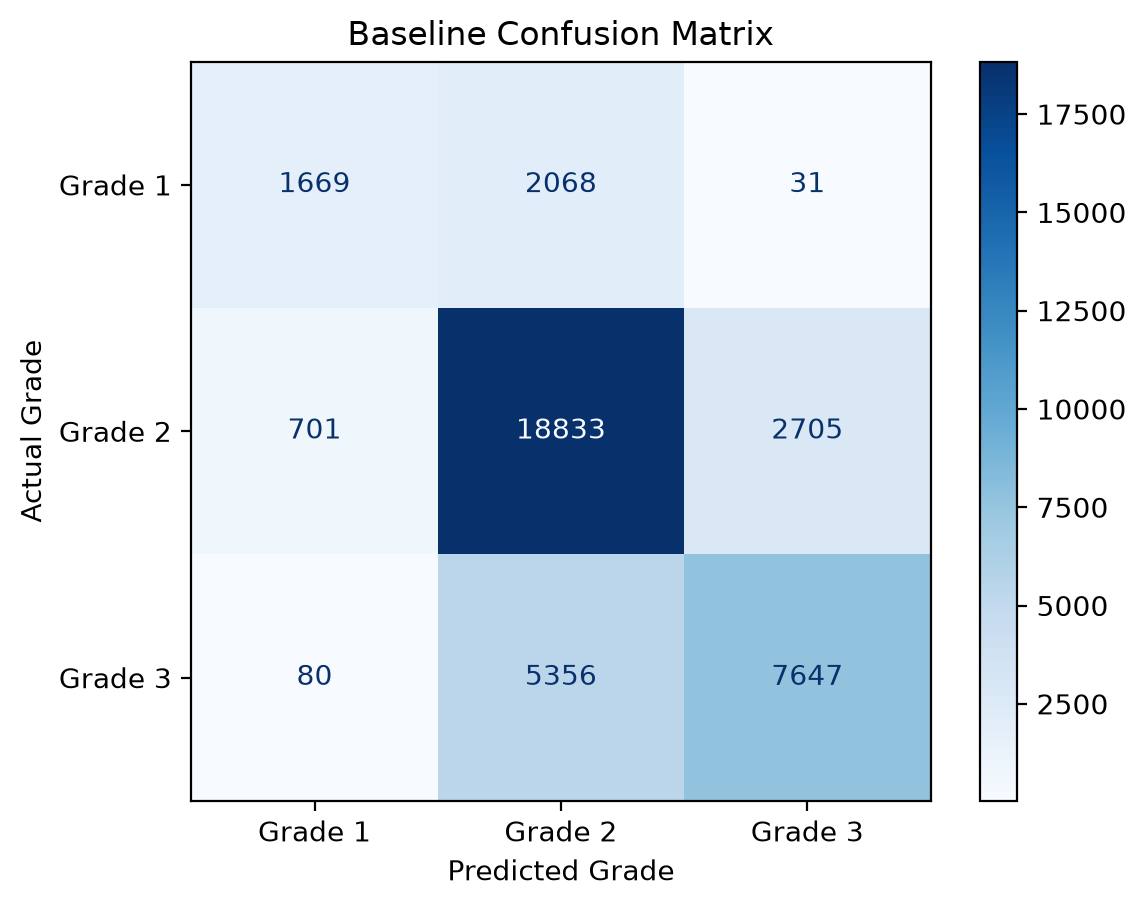

In [9]:
# --------------------------------------------------
# 1. 라이브러리
# --------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 2. 수치형 / 범주형 변수 구분
# --------------------------------------------------
cat_cols = X_train.select_dtypes(exclude=['number']).columns.tolist()
num_cols = X_train.select_dtypes(include=['number']).columns.tolist()

# --------------------------------------------------
# 3. 전처리 정의
# --------------------------------------------------

# 수치형: 결측치 중앙값 대체
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# 범주형: 결측치 최빈값 대체 + 원핫인코딩
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# --------------------------------------------------
# 4. XGBoost 모델 생성
# --------------------------------------------------
xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# --------------------------------------------------
# 5. 모델 학습
# --------------------------------------------------
xgb_model.fit(X_train, y_train)

# --------------------------------------------------
# 6. Validation 예측
# --------------------------------------------------
y_pred = xgb_model.predict(X_val)

# --------------------------------------------------
# 7. 성능 평가
# --------------------------------------------------
print("===== XGBoost Validation 평가 =====")

print("Accuracy :", round(accuracy_score(y_val, y_pred), 4))
print("Recall   :", round(recall_score(y_val, y_pred, average='macro'), 4))
print("Macro F1 :", round(f1_score(y_val, y_pred, average='macro'), 4))

print("\n===== Classification Report =====")
print(classification_report(y_val, y_pred, digits=4))

# --------------------------------------------------
# 8. 혼동행렬
# --------------------------------------------------
cm = confusion_matrix(y_val, y_pred, labels=[0, 1, 2])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Grade 1', 'Grade 2', 'Grade 3']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Baseline Confusion Matrix')
plt.xlabel('Predicted Grade')
plt.ylabel('Actual Grade')
plt.show()

### 2-2) 불균형 처리 비교

In [5]:
# Val Macro F1 기준
# CatBoost, XGBoost, Random Forest, LightGBM

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

# 1. 비교 모델
models = {
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0),
    'XGBoost': XGBClassifier(random_state=42, n_jobs=-1),
    'RandomForest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(random_state=42, verbosity=-1, n_jobs=-1)
}

# 2. 불균형 처리 방법
methods = ['None', 'Class Weight', 'SMOTE', 'SMOTENC', 'Under Sampling']

# 3. SMOTENC용 결측값 처리
smotenc_imputer = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', SimpleImputer(strategy='most_frequent'), cat_cols)
], verbose_feature_names_out=False).set_output(transform='pandas')

# 4. 파이프라인 생성
def make_pipe(model, method):

    if method == 'SMOTENC':
        return ImbPipeline([
            ('imputer', clone(smotenc_imputer)),
            ('sampler', SMOTENC(categorical_features=cat_cols, random_state=42)),
            ('prep', clone(tree_preprocessor)),
            ('model', clone(model))
        ])

    steps = [('prep', clone(tree_preprocessor))]

    if method == 'SMOTE':
        steps.append(('sampler', SMOTE(random_state=42)))

    elif method == 'Under Sampling':
        steps.append(('sampler', RandomUnderSampler(random_state=42)))

    steps.append(('model', clone(model)))
    return ImbPipeline(steps)


# 5. 평가 함수
def evaluate(y_true, pred):
    return [
        accuracy_score(y_true, pred),
        recall_score(y_true, pred, average='macro', zero_division=0),
        f1_score(y_true, pred, average='macro', zero_division=0)
    ]


# 6. 5-Fold + Validation 평가
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    for method in methods:

        print(name, method)
        scores = []

        for tr, va in cv.split(X_train, y_train):

            pipe = make_pipe(model, method)

            X_tr, X_va = X_train.iloc[tr], X_train.iloc[va]
            y_tr, y_va = y_train.iloc[tr], y_train.iloc[va]

            if method == 'Class Weight':
                weights = compute_sample_weight('balanced', y_tr)
                pipe.fit(X_tr, y_tr, model__sample_weight=weights)
            else:
                pipe.fit(X_tr, y_tr)

            pred = pipe.predict(X_va)
            scores.append(evaluate(y_va, pred))

        # Validation 평가
        pipe = make_pipe(model, method)

        if method == 'Class Weight':
            weights = compute_sample_weight('balanced', y_train)
            pipe.fit(X_train, y_train, model__sample_weight=weights)
        else:
            pipe.fit(X_train, y_train)

        val_pred = pipe.predict(X_val)
        val_scores = evaluate(y_val, val_pred)

        scores = np.array(scores)

        row = {'Model': name, 'Method': method}

        for i, metric in enumerate(['Accuracy', 'Recall', 'F1']):
            row[f'CV {metric} Mean'] = scores[:, i].mean()
            row[f'CV {metric} Std'] = scores[:, i].std()
            row[f'Val {metric}'] = val_scores[i]

        results.append(row)


# 7. 결과 DataFrame
result_df = pd.DataFrame(results)

result_df = result_df.sort_values(
    'Val F1', ascending=False
).reset_index(drop=True)

CatBoost None
CatBoost Class Weight
CatBoost SMOTE
CatBoost SMOTENC
CatBoost Under Sampling
XGBoost None
XGBoost Class Weight
XGBoost SMOTE
XGBoost SMOTENC
XGBoost Under Sampling
RandomForest None
RandomForest Class Weight
RandomForest SMOTE
RandomForest SMOTENC
RandomForest Under Sampling
LightGBM None
LightGBM Class Weight
LightGBM SMOTE
LightGBM SMOTENC
LightGBM Under Sampling


In [6]:
result_df

,Model,Method,CV Accuracy Mean,CV Accuracy Std,Val Accuracy,CV Recall Mean,CV Recall Std,Val Recall,CV F1 Mean,CV F1 Std,Val F1
0,CatBoost,SMOTENC,0.716594,0.002059,0.716552,0.647535,0.002388,0.651384,0.665089,0.002787,0.667081
1,CatBoost,SMOTE,0.716215,0.001416,0.717907,0.641652,0.002459,0.645944,0.662070,0.002563,0.665415
2,XGBoost,SMOTENC,0.714439,0.002439,0.714914,0.639569,0.002111,0.643392,0.660277,0.002106,0.662663
3,XGBoost,SMOTE,0.715382,0.002552,0.715426,0.635782,0.002891,0.638717,0.659151,0.002972,0.660986
4,RandomForest,Class Weight,0.689009,0.001371,0.692965,0.672556,0.001450,0.678589,0.655487,0.000728,0.660882
5,CatBoost,None,0.722333,0.001330,0.724456,0.625277,0.001639,0.627520,0.656845,0.001904,0.659283
6,RandomForest,SMOTENC,0.702176,0.002252,0.705295,0.640278,0.001492,0.643991,0.651971,0.002110,0.656106
7,XGBoost,None,0.723429,0.001411,0.720107,0.629589,0.002133,0.624762,0.660324,0.002279,0.655088
8,RandomForest,None,0.709401,0.001551,0.709875,0.623488,0.001353,0.625966,0.648436,0.001264,0.650338
9,LightGBM,SMOTENC,0.699304,0.002802,0.698465,0.633383,0.002793,0.636137,0.648151,0.003312,0.649324
